# Titanic で学ぶ機械学習の基本

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sriku2929/Open_seminar/blob/main/titanic/titanic_tutorial.ipynb)

1912年に沈没したタイタニック号の乗客データを使って、**「どんな人が生き残ったか」を予測するモデル**を作ります。

このノートブックでは、機械学習の基本的な流れを一通り体験します。

1. データを読み込む
2. データを眺める（どんな列があるか・欠損はあるか）
3. グラフで傾向をつかむ
4. 前処理（欠損を埋める・文字を数値に変える）
5. モデルを学習させる
6. 精度を確かめる
7. テストデータを予測して提出ファイルを作る

後半では、ここで学んだ流れを使って **Spaceship Titanic** に自分で取り組んでもらいます。

> 上から順に `Shift + Enter` でセルを実行していきましょう。

## 1. データを読み込む

データはGitHubに置いてあるので、URLを指定するだけで読み込めます。

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

BASE = "https://raw.githubusercontent.com/sriku2929/Open_seminar/main"
train = pd.read_csv(f"{BASE}/titanic/train.csv")
test = pd.read_csv(f"{BASE}/titanic/test.csv")

print("train:", train.shape)
print("test :", test.shape)

train: (891, 12)
test : (418, 11)


- **train**：答え（`Survived`）がついたデータ。これでモデルを学習させます。
- **test**：答えがないデータ。これを予測するのが目標です。

`(891, 12)` は「891行 × 12列」という意味です。

## 2. データを眺める

In [2]:
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


| 列名 | 意味 |
|---|---|
| PassengerId | 乗客ID |
| **Survived** | **生存したか（1=生存, 0=死亡）← 予測したいもの** |
| Pclass | 客室クラス（1=上流, 2=中流, 3=下層） |
| Name | 名前 |
| Sex | 性別 |
| Age | 年齢 |
| SibSp | 一緒に乗った兄弟・配偶者の数 |
| Parch | 一緒に乗った親・子どもの数 |
| Ticket | チケット番号 |
| Fare | 運賃 |
| Cabin | 客室番号 |
| Embarked | 乗船した港（C, Q, S） |

In [3]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


### 欠損値（データが空になっているところ）を確認

In [4]:
train.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

- `Age` が177件、`Cabin` が687件、`Embarked` が2件欠けています。
- 多くのモデルは欠損があると学習できないので、あとで埋める必要があります。

### 全体の生存率

In [5]:
train['Survived'].mean()

np.float64(0.3838383838383838)

約38%しか生き残っていません。**全員「死亡」と予測しても約62%は当たる**ことは覚えておきましょう。モデルの精度はこれより高くないと意味がありません。

## 3. グラフで傾向をつかむ

どの特徴が生存と関係していそうかを見ていきます。

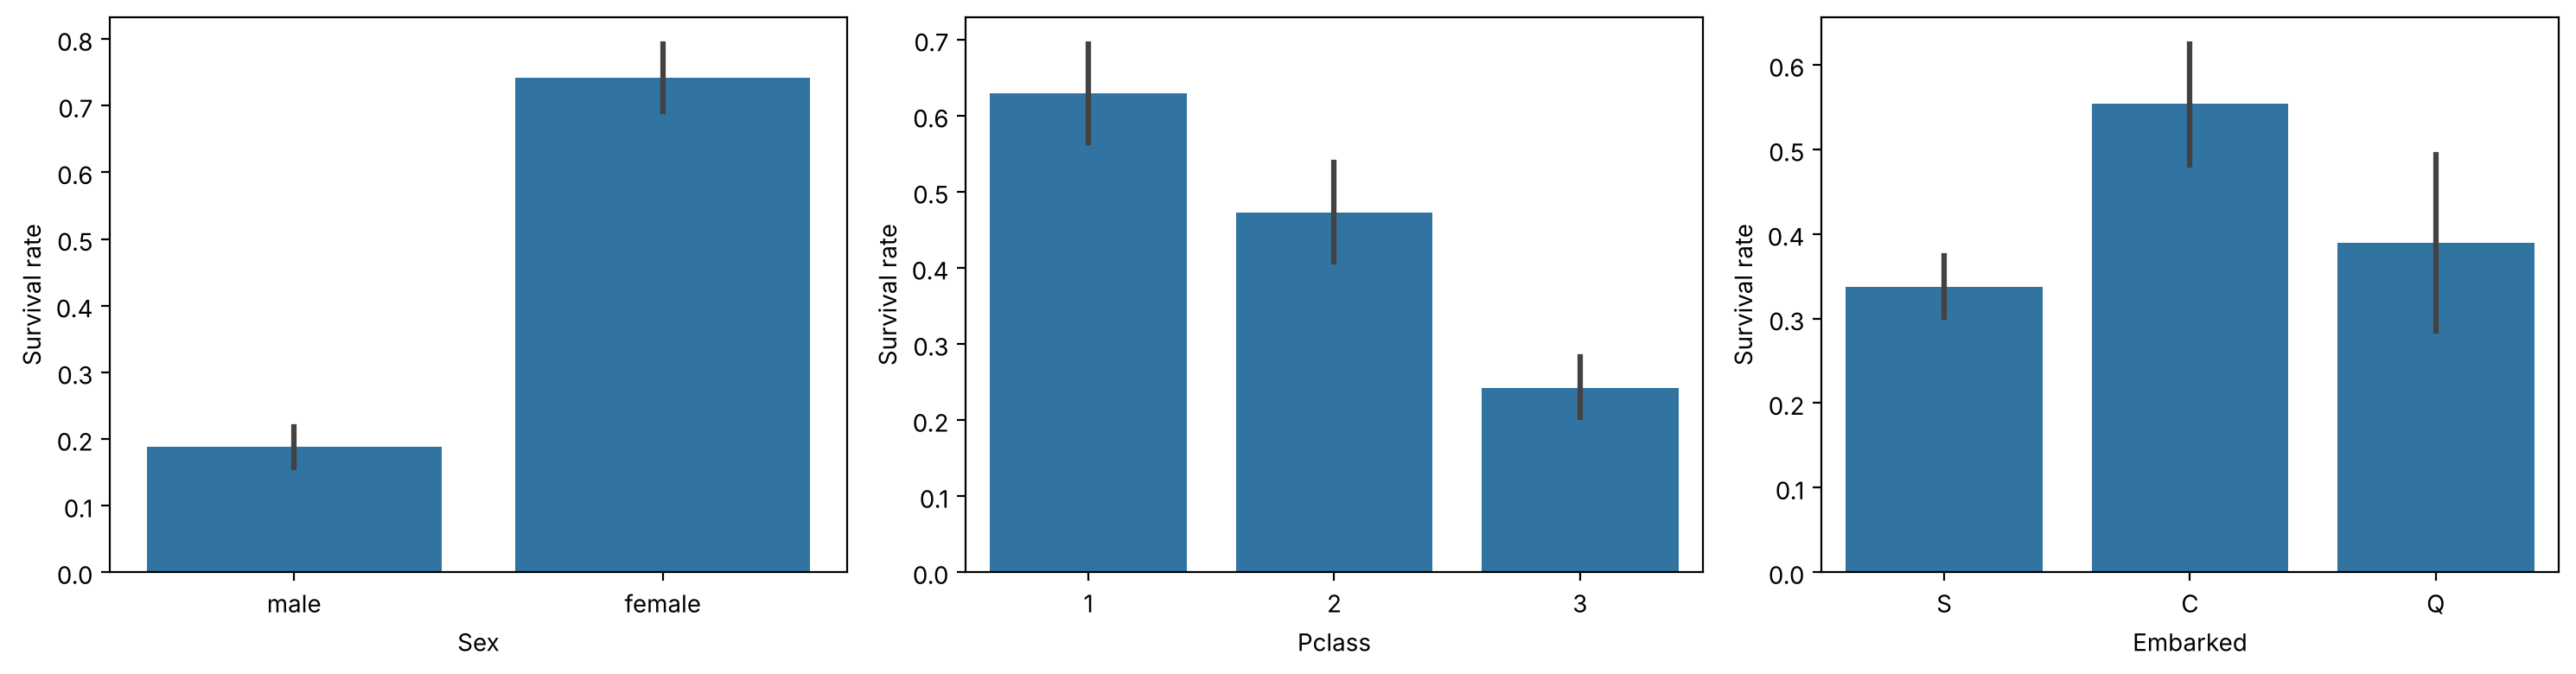

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.barplot(data=train, x="Sex", y="Survived", ax=axes[0])
sns.barplot(data=train, x="Pclass", y="Survived", ax=axes[1])
sns.barplot(data=train, x="Embarked", y="Survived", ax=axes[2])
for ax in axes:
    ax.set_ylabel("Survival rate")
plt.tight_layout()
plt.show()

- **性別**：女性の生存率が圧倒的に高い（「女性と子どもを先に救命ボートへ」）
- **客室クラス**：1等客室ほど生存率が高い

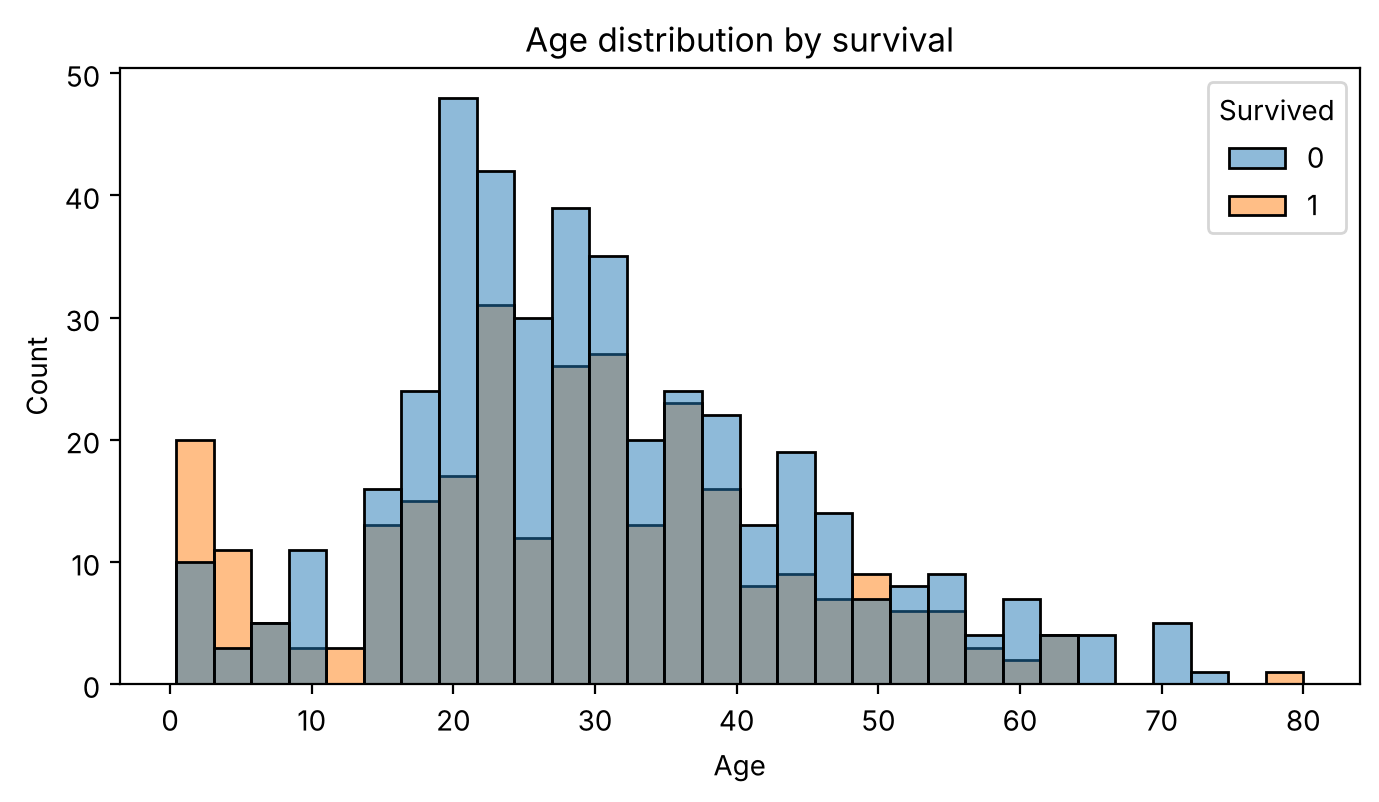

In [7]:
plt.figure(figsize=(8, 4))
sns.histplot(data=train, x="Age", hue="Survived", bins=30, kde=False)
plt.title("Age distribution by survival")
plt.show()

- **年齢**：子ども（10歳未満）は生存者の割合が高めです。

## 4. 前処理

モデルに渡すには、データを **「欠損がない」「すべて数値」** の形にする必要があります。

train と test には同じ処理をしないといけないので、関数にまとめておきます。

In [8]:
def preprocess(df):
    df = df.copy()

    # 性別を数値に（male=0, female=1）
    df["Sex"] = df["Sex"].map({"male": 0, "female": 1})

    # 年齢の欠損は「trainの中央値」で埋める
    df["Age"] = df["Age"].fillna(train["Age"].median())

    # 運賃の欠損（testに1件ある）も中央値で埋める
    df["Fare"] = df["Fare"].fillna(train["Fare"].median())

    # 乗船港の欠損は一番多い "S" で埋め、ダミー変数に変換
    df["Embarked"] = df["Embarked"].fillna("S")
    df = pd.get_dummies(df, columns=["Embarked"], dtype=int)

    # 家族の人数（自分を含む）という新しい特徴を作る
    df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

    return df

train_p = preprocess(train)
test_p = preprocess(test)

features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare",
            "FamilySize", "Embarked_C", "Embarked_Q", "Embarked_S"]
X = train_p[features]
y = train_p["Survived"]
X_test = test_p[features]

X.head()

,Pclass,Sex,Age,SibSp,Parch,Fare,FamilySize,Embarked_C,Embarked_Q,Embarked_S
0,3,0,22.0,1,0,7.2500,2,0,0,1
1,1,1,38.0,1,0,71.2833,2,1,0,0
2,3,1,26.0,0,0,7.9250,1,0,0,1
3,1,1,35.0,1,0,53.1000,2,0,0,1
4,3,0,35.0,0,0,8.0500,1,0,0,1


ポイント：
- **欠損の埋め方**：中央値で埋めるのが一番シンプルな方法です。
- **ダミー変数**：`Embarked`（C/Q/S）のような文字のカテゴリは、`Embarked_C`, `Embarked_Q`, `Embarked_S` という0/1の列に分けます。
- **特徴量エンジニアリング**：`FamilySize` のように、元の列を組み合わせて新しい特徴を作ることもできます。
- `Name`, `Ticket`, `Cabin` は今回は使いません（工夫すれば使えます）。

## 5. モデルを学習させる

答えのあるtrainを **学習用（80%）** と **検証用（20%）** に分けます。

学習に使ったデータで精度を測ると、モデルが答えを「暗記」しているだけでも高く出てしまいます。だから、**モデルが見ていないデータ** で確かめます。

In [9]:
from sklearn.model_selection import train_test_split

X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X_tr.shape, X_val.shape)

(712, 10) (179, 10)


### モデル①：ロジスティック回帰

「生存する確率」を計算する、シンプルで解釈しやすいモデルです。

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

lr = LogisticRegression(max_iter=1000)
lr.fit(X_tr, y_tr)
print("ロジスティック回帰 accuracy:", accuracy_score(y_val, lr.predict(X_val)))

ロジスティック回帰 accuracy: 0.8044692737430168


### モデル②：ランダムフォレスト

たくさんの決定木を作って多数決をとるモデルです。複雑なパターンも捉えられます。

In [11]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=200, max_depth=6, random_state=42)
rf.fit(X_tr, y_tr)
print("ランダムフォレスト accuracy:", accuracy_score(y_val, rf.predict(X_val)))

ランダムフォレスト accuracy: 0.8044692737430168


今回はどちらも約80%で、全員「死亡」と予測した場合の約62%を大きく上回っています。

## 6. どの特徴が効いているか

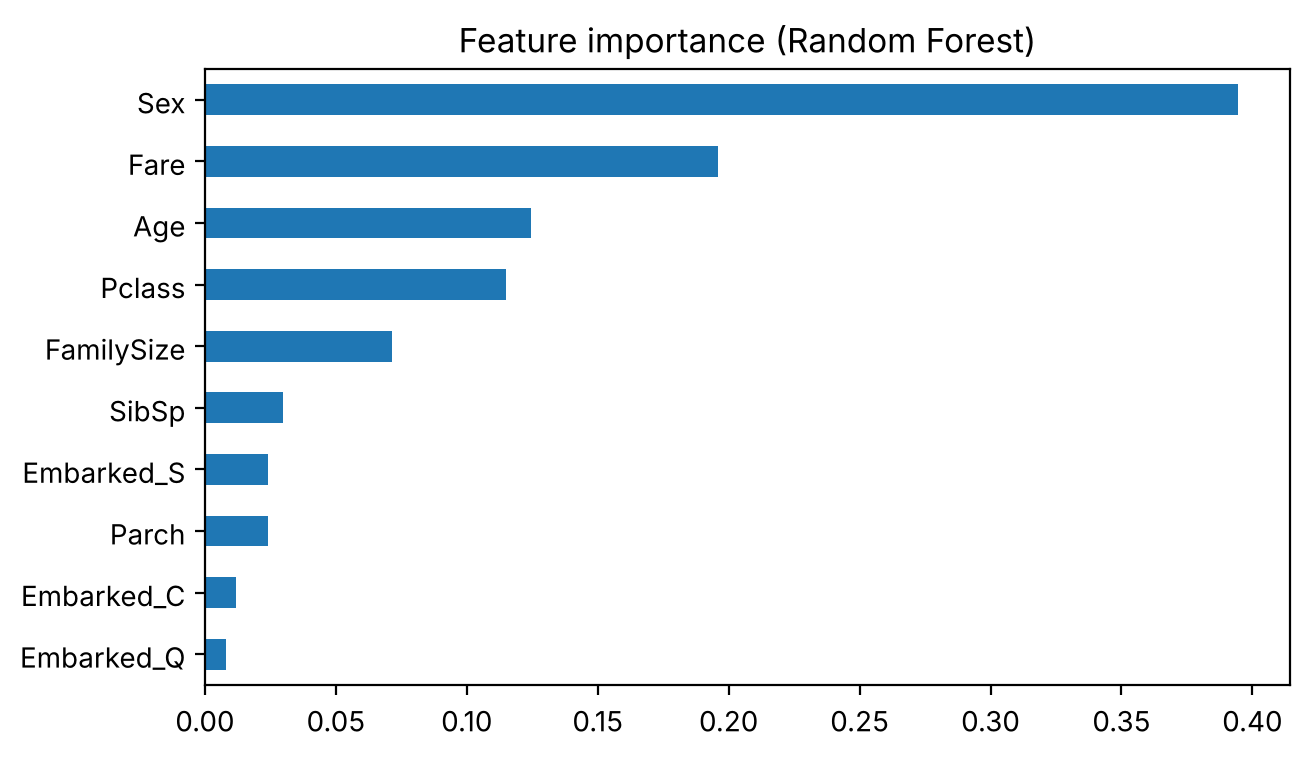

In [12]:
importances = pd.Series(rf.feature_importances_, index=features).sort_values()
importances.plot(kind="barh", figsize=(7, 4), title="Feature importance (Random Forest)")
plt.show()

グラフで見た通り、**性別・運賃・年齢・客室クラス** が重要な特徴になっています。

## 7. テストデータを予測して提出ファイルを作る

最後に、train **全体** でモデルを学習し直してからtestを予測します。

In [13]:
model = RandomForestClassifier(n_estimators=200, max_depth=6, random_state=42)
model.fit(X, y)

submission = pd.DataFrame({
    "PassengerId": test["PassengerId"],
    "Survived": model.predict(X_test),
})
submission.to_csv("submission.csv", index=False)
submission.head()

,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1


`submission.csv` ができました。Colabなら左のファイルアイコンからダウンロードできます。

[Kaggle の Titanic コンペ](https://www.kaggle.com/competitions/titanic) の「Submit Prediction」から提出すると、スコアが確認できます（Kaggleアカウントと参加登録が必要です）。

---
## 次は Spaceship Titanic に挑戦！

今度は宇宙船「Spaceship Titanic」の乗客が **別次元に転送されたか（`Transported`）** を予測します。

やることは今回とまったく同じ流れです。

1. データを読み込む → `f"{BASE}/spaceship-titanic/train.csv"`
2. 列の意味と欠損を確認する
3. グラフで傾向を見る
4. 前処理（欠損を埋める・文字を数値に）
5. モデルを学習・検証する
6. 予測して提出ファイルを作る

ヒント：
- `Cabin` は `B/0/P` のような形です。`/` で分けると「デッキ・番号・左右」の3つの特徴になります。
- `RoomService`, `FoodCourt` などの船内での支出は、合計すると役に立つかもしれません。
- `CryoSleep`（冷凍睡眠）の人は支出が0のはず……？